# Question 8 - Regional climate-extreme exposure map

This notebook completes Question 8 by mapping the `median_val` estimates of additional people exposed to climate extremes due to the CO2 emissions of the Permian Delaware Tight carbon bomb. It uses the 2025 birth cohort and makes one panel for each of the six hazards.

The assignment supplies country polygons, not regional polygons. The country-border GeoDataFrame already has a `region` field, so the notebook dissolves country boundaries by this field to construct `gdf_regions_border`. The dataset also includes a `World` aggregate; it has no separate polygon and is intentionally left out of the regional map. The eight geographic regions are displayed.

The source medians are used as supplied, including small negative values where present. These values can represent a modelled decrease in additional exposure and are not clipped to zero. A diverging colour scale is used for hazards whose regional medians span zero. Each hazard panel has its own colour scale because their exposure magnitudes differ substantially.

## Step 1 - Locate the project and load the Question 8 functions

In [1]:
from pathlib import Path
import sys

project_root = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "Data" / "gdf_country_borders.pkl").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find Data/gdf_country_borders.pkl.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.question8_regional_map import (
    create_gdf_regions_border,
    get_regional_medians,
    load_regional_dataset,
    plot_regional_exposure_map,
)

regional_dataset = load_regional_dataset(
    project_root / "Data" / "question7_regions_by_birth_year.pkl",
    project_root / "Data",
)
print(regional_dataset.sizes)

Frozen({'birth_years': 39, 'project': 1, 'extreme': 6, 'region': 9, 'samples': 1})


## Step 2 - Build `gdf_regions_border`

The supplied border GeoDataFrame has one geometry per country and stores each country's region in a column. Dissolving on `region` unions the country polygons into one geometry per region. We verify its columns and resulting region names before plotting.

In [2]:
gdf_regions_border = create_gdf_regions_border(
    project_root / "Data" / "gdf_country_borders.pkl"
)
print("CRS:", gdf_regions_border.crs)
print("Geographic regions:", gdf_regions_border["region"].tolist())
gdf_regions_border.drop(columns="geometry").head()

CRS: EPSG:4326
Geographic regions: ['Africa', 'Asia', 'Australasia', 'Central and South America', 'Europe', 'North America', 'Polar Regions', 'Small Islands']


,region,abbreviation
0,Africa,DZA
1,Asia,AFG
2,Australasia,AUS
3,Central and South America,ARG
4,Europe,ALB


## Step 3 - Inspect the 2025 regional median values

Each hazard has one median value per region. `World` is a total across all regions rather than an individual map shape, so the map step excludes it while retaining the source value in the merged dataset.

In [3]:
regional_medians_2025 = get_regional_medians(
    regional_dataset,
    extreme="heatwavedarea",
    birth_year=2025,
)
regional_medians_2025

,region,median_val
0,Africa,5.244709e+06
1,Asia,8.622960e+06
2,Australasia,3.368061e+04
3,Central and South America,1.203131e+06
4,Europe,8.062672e+05
5,North America,6.050070e+05
6,Polar Regions,5.110360e+02
7,Small Islands,4.699514e+03
8,World,1.680427e+07


## Step 4 - Plot and save the 2025 regional exposure maps

The figure contains six maps, one per climate extreme. Colour represents the median number of additional people exposed in each region. The colorbar is independently scaled for each hazard, so compare colours within a panel rather than across different hazards. The high-resolution figure is saved to `figures/question8_regional_exposure_2025.png`.

Mapped 8 regions for each of six hazards.


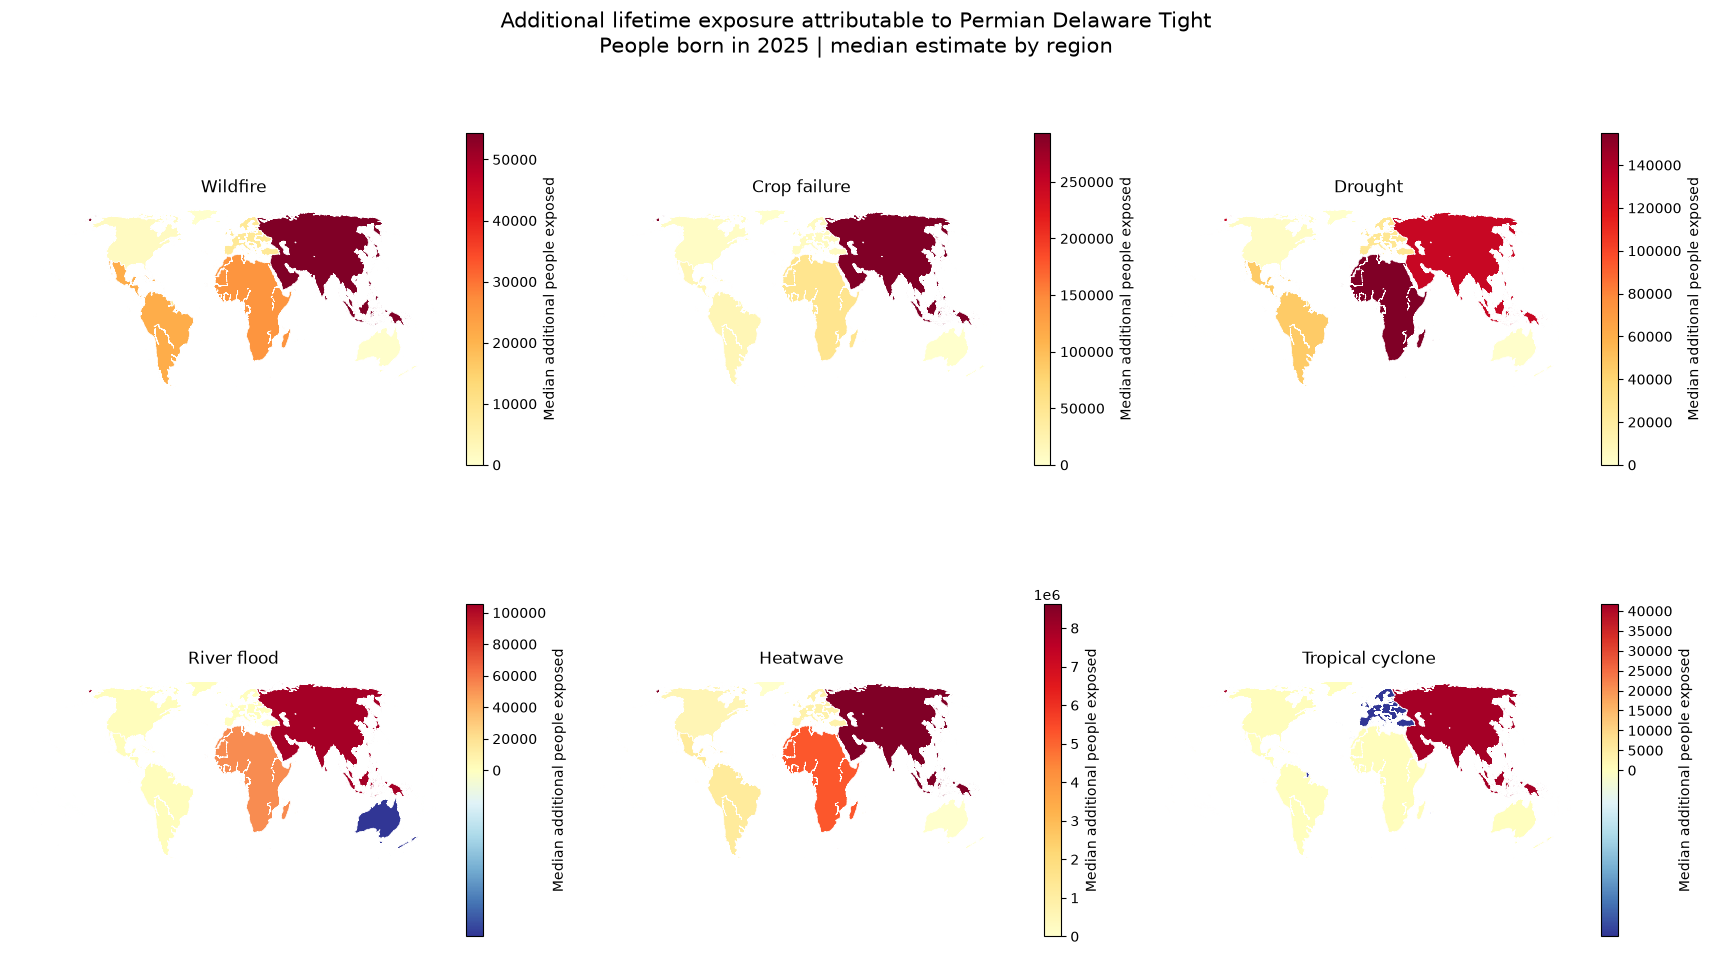

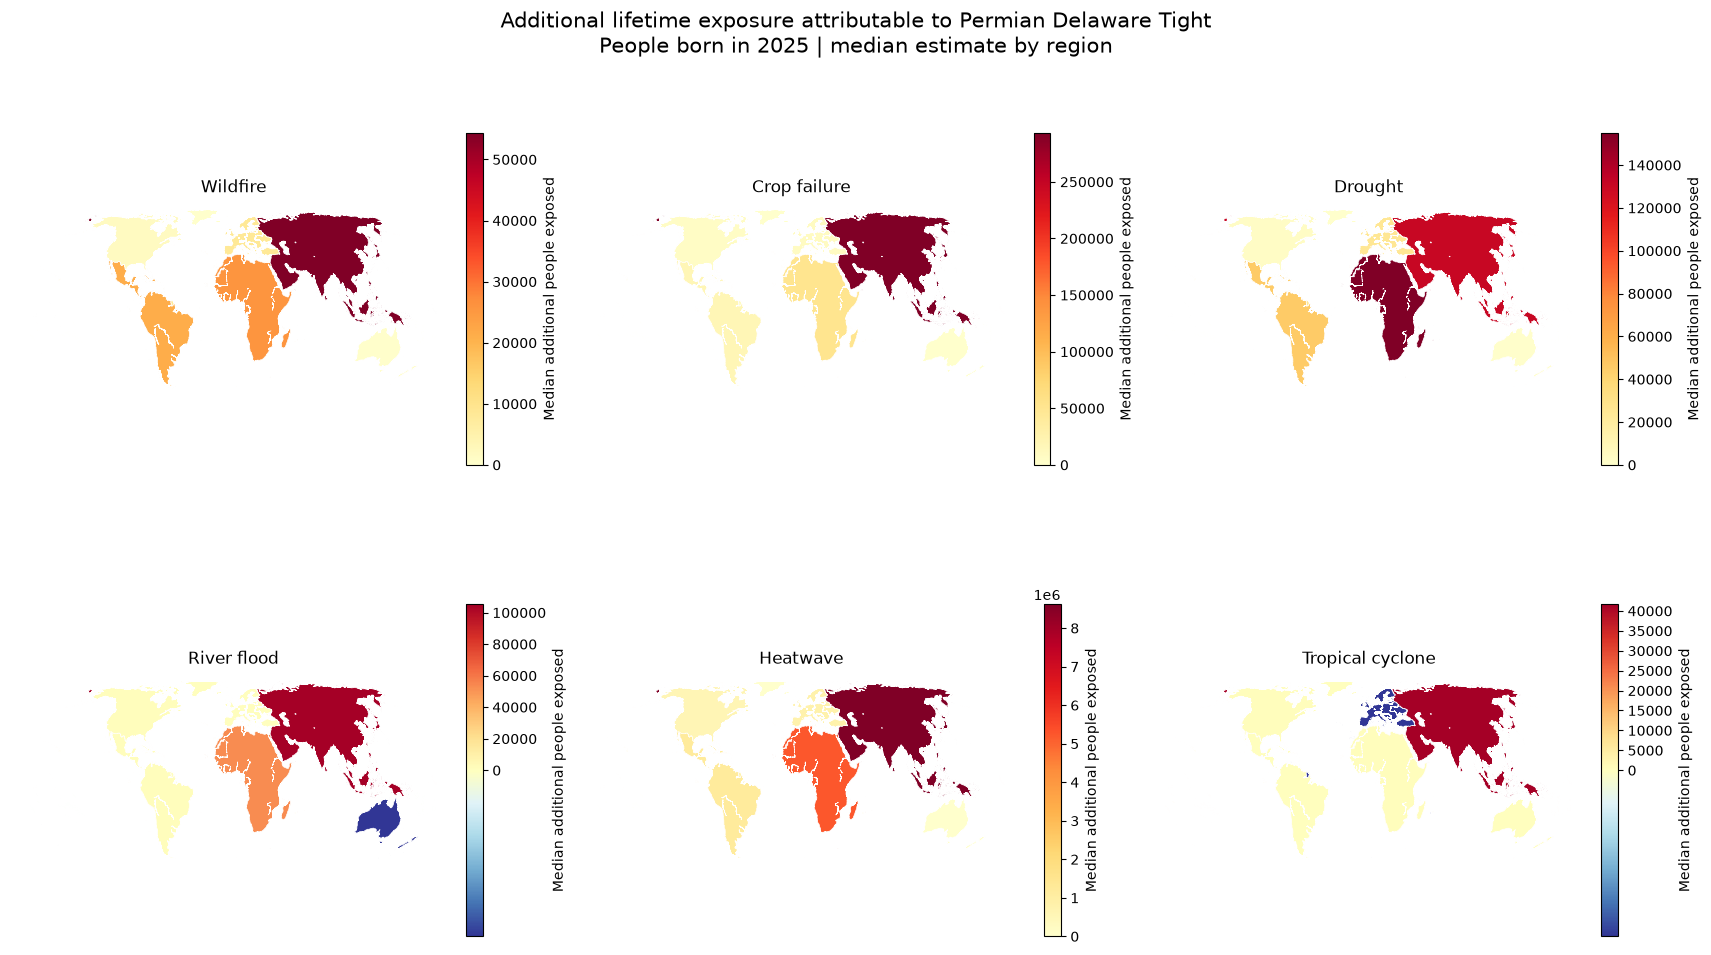

In [4]:
regional_figure, regional_axes, mapped_regions = plot_regional_exposure_map(
    regional_dataset,
    gdf_regions_border,
    birth_year=2025,
    output_path=project_root / "figures" / "question8_regional_exposure_2025.png",
)
print(f"Mapped {len(mapped_regions)} regions for each of six hazards.")
regional_figure